# Phase 4 — Destination Research

**Main objective**: add a specific branch to the graph designed to help users find the best destination based on their requirements. An initial router determines whether this branch should be executed, depending on whether the user has already specified a destination.

Once the router is executed, the branch will:

* Generate a shortlist of candidate destinations.
* Use the available MCPs to research each candidate **only when needed**. If the llm can answer using its own general knowledge, we avoid using MCPs' tools to reduce costs associated with the tokens they generate.
* Score and compare candidate destinations.
* Give a ranking to each destination based on its relevance and supporting evidence.

In [2]:
# Imports and environment setup

import os
import json
import uuid
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display, Markdown
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, ToolMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.tools import tool, ToolRuntime
from langgraph.types import Command, interrupt
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langchain_mcp_adapters.client import MultiServerMCPClient
from pydantic import BaseModel, Field
from datetime import datetime

load_dotenv(override=True)

True

## *Code inherited from phase3.ipynb*

### MCPs

#### IMPORTANT: Adjustment for Windows

The following adjustment is needed when running MCP servers via stdio inside a Jupyter notebook on Windows. Jupyter's stderr stream is not a regular file, which can cause the MCP Python SDK to fail when launching the server. This workaround redirects the server's error output to DEVNULL. On macOS and Linux, no adjustment is required.

In [3]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

Applied the Windows adjustment


In [4]:
mcp_client = MultiServerMCPClient({
        "ticketlens": {
            "transport": "http",
            "url": "https://mcp.ticketlens.com/",
        },
        # Alternative OpenMeteo MCP for testing weather tools
        # https://github.com/cyanheads/open-meteo-mcp-server
        "weather": {
            "transport": "streamable_http",
            "url": "https://open-meteo.caseyjhand.com/mcp",
        },
        "trvl": {
            "transport": "stdio",
            "command": "trvl",
            "args": ["mcp"],
        },
        "octotrip-rental-cars": {
            "transport": "http",
            "url": "https://mcp.octotrip.app/rental-cars/mcp",
        }
    }
)

tools = await mcp_client.get_tools()
print(f"Loaded {len(tools)} tools.")

weather_tools = []
ticketlens_tool_names = {"search_pois", "search_tours", "get_tour"}
ticketlens_tools = []
trvl_tool = None
rental_cars_tool = None

counter = 0

# Extract tools from each MCP
for t in tools:
    
    if t.name.startswith("openmeteo"):
        weather_tools.append(t)

    elif t.name in ticketlens_tool_names:
        ticketlens_tools.append(t)

    elif t.name == "travel":
        trvl_tool = t

    elif t.name == "search": 
        # Renamed to avoid conflicts with other MCPs
        t.name = "search_rental_cars"
        rental_cars_tool = t
    else:
        continue

    print(f"{t.name}: {t.description}")
    counter += 1

print(f"{counter} tools available for the agent.")

Loaded 18 tools.
search_tours: Search tour offers by query, POI, city, destination, price and tags
get_tour: Fetch canonical tour record by tour_id
search_pois: Resolve POI names, aliases, and possible candidates before tour search
openmeteo_search_locations: Resolve a place name to ranked coordinate matches with country, region, elevation, timezone, and population. Required prerequisite for name-based queries — all weather tools take latitude/longitude, not place names. Search by a bare place name (city, region, or landmark); never fold a qualifier into it — pass "Baoding", not "Baoding Hebei", and "Paris", not "Paris, France". To disambiguate places that share a name, set the country input (ISO 3166-1 alpha-2, e.g. "US") and/or read the admin1 and country fields on each ranked result — admin1 is a result field for choosing among matches, not a search input. Returns up to 10 matches ranked by population/relevance.
openmeteo_get_elevation: Terrain elevation from the Copernicus Digital 

### Define the shared `TravelState`

In [5]:
# Define the shared TravelState
class TravelRequirements(BaseModel):
    origin: str | None = None
    destination: str | None = None
    travel_dates: str | None = None
    duration_days: int | None = None
    travelers: int | None = None
    budget: float | None = None
    currency: str | None = None
    interests: list[str] = Field(default_factory=list)
    constraints: list[str] = Field(default_factory=list)

class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None

#### Tool for updating the travel state

In [6]:
# Auxliary functions for update_requirements tool
def normalize_list(value: list[str] | str | None) -> list[str]:
    """
    Normalize a value into a list of strings.

    Accepts None, an existing list, or a JSON-encoded list returned as a string.
    If the string is not valid JSON, it is treated as a single list item.
    """
    if value is None:
        return []

    if isinstance(value, list):
        return value

    # The model may return the list as a JSON-encoded string.
    if isinstance(value, str):
        try:
            parsed = json.loads(value)

            # Return the parsed value if it is a valid JSON list.
            if isinstance(parsed, list):
                return parsed

        except json.JSONDecodeError:
            pass

        return [value]

    # Fallback for unexpected input types.
    return []

In [7]:
@tool
def update_requirements(
    runtime: ToolRuntime,
    origin: str | None = None,
    destination: str | None = None,
    travel_dates: str | None = None,
    duration_days: int | None = None,
    travelers: int | None = None,
    budget: float | None = None,
    currency: str | None = None,
    add_interests: list[str] | str | None = None,
    remove_interests: list[str] | str | None = None,
    add_constraints: list[str] | str | None = None,
    remove_constraints: list[str] | str | None = None,
) -> Command:
    """
    Update the user's current travel requirements.

    Only provide fields that have been explicitly added or changed by the user.

    For interests and constraints:
    - Use add_interests to add new interests.
    - Use remove_interests to remove previous interests.
    - Use add_constraints to add new constraints.
    - Use remove_constraints to remove previous constraints.

    Do not invent requirements or modify information that the user has not
    explicitly changed.
    """

    # ToolRuntime gives the tool access to the current LangGraph state,
    # including the TravelRequirements stored in the current graph execution.
    current = runtime.state["requirements"]

    if current is None:
        current = TravelRequirements()

    updated = current.model_copy()

    # Normalize list arguments in case the model sends JSON strings.
    add_interests = normalize_list(add_interests)
    remove_interests = normalize_list(remove_interests)
    add_constraints = normalize_list(add_constraints)
    remove_constraints = normalize_list(remove_constraints)

    # Update scalar fields only when explicitly provided
    if origin is not None:
        updated.origin = origin

    if destination is not None:
        updated.destination = destination

    if travel_dates is not None:
        updated.travel_dates = travel_dates

    if duration_days is not None:
        updated.duration_days = duration_days

    if travelers is not None:
        updated.travelers = travelers

    if budget is not None:
        updated.budget = budget

    if currency is not None:
        updated.currency = currency

    # Update interests
    if add_interests:
        updated.interests = list(
            dict.fromkeys(
                updated.interests + add_interests
            )
        )

    if remove_interests:
        updated.interests = [
            interest
            for interest in updated.interests
            if interest not in remove_interests
        ]

    # Update constraints
    if add_constraints:
        updated.constraints = list(
            dict.fromkeys(
                updated.constraints + add_constraints
            )
        )

    if remove_constraints:
        updated.constraints = [
            constraint
            for constraint in updated.constraints
            if constraint not in remove_constraints
        ]

    # Command tells LangGraph to update the graph state.
    # The new TravelRequirements replaces the current "requirements" value.
    return Command(
        update={
            "requirements": updated,
            "messages": [
                ToolMessage(
                    content="Travel requirements updated successfully.",
                    tool_call_id=runtime.tool_call_id,
                )
            ],
        }
    )

### Travel Planner Agent

In [8]:
# Same as phase3, but summarized to save tokens
# New Destination research section added
SYSTEM_PROMPT = """
You are a Travel Planner specialized in personalized trip planning.
Help users make informed decisions based on their requirements.

Behavior:
- Be helpful, practical, clear, and honest about uncertainty.
- Prioritize explicit user requirements and ask when essential information is missing.
- Do not invent facts, prices, availability, or other real-world data.
- Explain important recommendations and avoid generic suggestions.

Destination research:
- Treat previously presented destination candidates as suggestions, not as a decision.
- If the user selects or specifies a destination, use update_requirements to save it and continue planning for that destination.

Requirements:
- Treat current requirements as the trip's current state.
- Use update_requirements when the user adds, changes, removes, or reverses a requirement.
- Only update explicitly provided information; preserve unchanged requirements.
- When requirements conflict, follow the latest explicit instruction.

Tools:
- Use external tools when relevant and prefer their results for current or specific data.
- Use the minimum tools necessary.
- Do not start searching for transportation from origin (flight, train, bus...), accommodations, weather, or other travel options immediately after a destination is selected if essential trip details or the user's intended next step are still missing.
- When the user has not explicitly asked for a specific search or action, ask what they would like to plan next.
- Never claim to have searched or verified information unless a tool returned it.
- If a tool cannot provide the requested information, state the limitation rather than inventing an answer.
- Clearly distinguish tool results from general knowledge.
- Do not assume tool results guarantee current prices or availability unless explicitly provided.
- Use the current date/time tool whenever the current date or year is relevant to interpreting dates or travel requirements.

trvl (specific guidelines for 'travel' tool use):
- For hotel/accommodation recommendations, prefer search_accommodations over search_hotels.
- For search_accommodations, pass the known location, check_in, check_out, guests, currency and budget, and use max_candidates=5 and max_offers=5 unless the user requests a broader search.
- For flights, use intent=flights with origin, destination and departure_date. For round trips, also provide return_date. Use passengers when provided.
- Use search_hotels for broad hotel discovery when appropriate.
- For ground transport, use intent=ground and provide from, to, date and type when known. type must be one of: train, bus, ferry.
- For rental cars, use search_rental_cars instead of 'travel' tool.

Scope:
- Only answer questions related to travel planning and your capabilities.
- If the user asks about something outside your scope, briefly explain that you cannot help with it.
"""

In [9]:
def sanitize_messages_for_llm(messages):
    """
    Auxiliary function for removing file/resource blocks from ToolMessages before 
    sending them to OpenAI Chat Completions.

    This fixes the error "OpenAI Chat Completions does not support file URLs." that 
    occured passing the trvl tool's response to the LLM.

    The original messages remain unchanged in LangGraph state.
    """

    sanitized = []

    for message in messages:

        if isinstance(message, ToolMessage) and isinstance(message.content, list):

            text_blocks = []

            for block in message.content:
                if (
                    isinstance(block, dict)
                    and block.get("type") == "text"
                    and "text" in block
                ):
                    text_blocks.append(block["text"])

            if text_blocks:
                sanitized.append(
                    ToolMessage(
                        content="\n".join(text_blocks),
                        tool_call_id=message.tool_call_id,
                        name=message.name,
                    )
                )

            else:
                sanitized.append(message)

        else:
            sanitized.append(message)

    return sanitized

In [10]:
# New tool
@tool
def get_current_date() -> str:
    """Return the current date in YYYY-MM-DD format."""
    return datetime.now().strftime("%Y-%m-%d")

In [11]:
# ---- LLM Node ----
llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

# Add tools to the LLM, including the ones from MCPs
tools = [
    update_requirements, get_current_date, 
    *ticketlens_tools, *weather_tools, trvl_tool, rental_cars_tool
]
llm_with_tools = llm.bind_tools(tools)

async def llm_node(state: TravelState) -> dict:
    # Extract the current requirements from the state
    current_requirements = state["requirements"]
    requirements_context = SystemMessage(
        content=f"""
Current travel requirements:

{current_requirements}
"""
    )

    # Add the current requirements to the system prompt + messages
    messages = [
        SystemMessage(content=SYSTEM_PROMPT),
        requirements_context, 
        *sanitize_messages_for_llm(state["messages"]),
    ]

    response = await llm_with_tools.ainvoke(messages)

    return {"messages": [response]}

## Implement requirements extraction node

This node is responsible for extracting user requirements and incorporating them into the graph state. In this case, we use the same LLM as in the previous phases, but we now **reduce its reasoning effort** to obtain faster and more cost-effective responses.

In [12]:
REQUIREMENTS_EXTRACTION_PROMPT = """
Extract the user's explicit travel requirements into the provided schema.

Only include information explicitly stated by the user.
Do not infer preferences, constraints, destinations, dates, budgets, or other values.

Preserve the user's meaning when normalizing values such as dates and currency.
Leave unknown fields empty.
"""

In [13]:
low_reasoning_llm = ChatOpenAI(
    model="xiaomi/mimo-v2.5",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),

    # OpenRouter-specific parameters
    extra_body={
        "reasoning": {
            "effort": "minimal",
        }
    },
)

requirements_llm = low_reasoning_llm.with_structured_output(
    TravelRequirements
)

async def extract_requirements(state: TravelState):
    response = await requirements_llm.ainvoke([
        SystemMessage(content=REQUIREMENTS_EXTRACTION_PROMPT),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"requirements": response}

### Test the node with different prompts

In [23]:
prompt1 = "I'm going to Paris from September 10 to September 17, 2026 for two people. My budget is €1,000."
prompt2 = "I want to travel to Japan for about two weeks in April. There will be three of us. We're interested in food and culture."
prompt3 = "Find me a beach destination in Europe for a week in July. I'm traveling alone and want to spend around €1,500."
prompt4 = "I want to visit Rome. I haven't decided the dates yet, but I'll be traveling with my partner. We prefer cultural activities and have a budget of €2,000."

In [28]:
for prompt in [prompt1, prompt2, prompt3, prompt4]:
    state = {
        "messages": [HumanMessage(content=prompt)],
        "requirements": None,
    }

    result = await extract_requirements(state)
    print(prompt)
    print(result["requirements"])
    print("-" * 80)

I'm going to Paris from September 10 to September 17, 2026 for two people. My budget is €1,000.
origin='' destination='Paris' travel_dates='2026-09-10 to 2026-09-17' duration_days=7 travelers=2 budget=1000.0 currency='EUR' interests=[] constraints=[]
--------------------------------------------------------------------------------
I want to travel to Japan for about two weeks in April. There will be three of us. We're interested in food and culture.
origin=None destination='Japan' travel_dates='April' duration_days=None travelers=3 budget=None currency=None interests=['food', 'culture'] constraints=[]
--------------------------------------------------------------------------------
Find me a beach destination in Europe for a week in July. I'm traveling alone and want to spend around €1,500.
origin='' destination='' travel_dates='' duration_days=7 travelers=1 budget=1500.0 currency='EUR' interests=[] constraints=['destination_type: beach', 'destination_region: Europe', 'duration: 1 week',

## Implement the research router

The router is implemented as an LLM call that returns only whether or not destination search mode should be enabled. Since the task is simple in this case, a **lighter model** is used to reduce costs and improve response time.

In [14]:
class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None
    destination_research_needed: bool # <-- New field

In [15]:
class ResearchDecision(BaseModel):
    needs_research: bool

In [16]:
RESEARCH_ROUTER_PROMPT = """
You are a travel-planning router.

Decide whether destination research is needed.

Set needs_research=true when the user has not committed to a single destination
and would benefit from discovering, comparing, or selecting destinations.
This includes requests that provide multiple destinations and ask to compare
or choose between them.

Set needs_research=false only when the user has clearly chosen one specific
destination, even if they want to research hotels, flights, activities, or
other options there.

Base the decision only on the user's request. Do not invent requirements.
"""

In [17]:
light_llm = ChatOpenAI(
    model="google/gemma-3-12b-it",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY"),
)

structured_router_llm = light_llm.with_structured_output(ResearchDecision)

async def research_router(state: TravelState):
    response = await structured_router_llm.ainvoke([
        SystemMessage(content=RESEARCH_ROUTER_PROMPT),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {"destination_research_needed": response.needs_research}

### Check if the router decides correctly

In [15]:
async def test_router(prompt: str):
    state = {
        "messages": [HumanMessage(content=prompt)],
        "requirements": None,
        "destination_research_needed": False,
    }

    result = await research_router(state)

    print(f"Prompt: {prompt}")
    print(f"needs_research: {result['destination_research_needed']}")

In [16]:
await test_router(
    "I want to travel somewhere in Europe in September. "
    "Find me some good destinations for food and culture."
) # True

await test_router(
    "I'm going to Paris in September. Find me suitable hotels for two people."
) # False

await test_router(
    "Compare Paris, Rome and Barcelona for a week-long trip in September "
    "and tell me which one is best."
) # True

Prompt: I want to travel somewhere in Europe in September. Find me some good destinations for food and culture.
needs_research: True
Prompt: I'm going to Paris in September. Find me suitable hotels for two people.
needs_research: False
Prompt: Compare Paris, Rome and Barcelona for a week-long trip in September and tell me which one is best.
needs_research: True


## Implement destination research node

In [18]:
class DestinationCandidate(BaseModel):
    destination: str
    score: float
    reason: str

class DestinationResearchResult(BaseModel):
    candidates: list[DestinationCandidate]

In [19]:
class TravelState(TypedDict):
    messages: Annotated[list, add_messages]
    requirements: TravelRequirements | None
    # New fields
    destination_research_needed: bool 
    destination_candidates: list[DestinationCandidate]

In [20]:
DESTINATION_RESEARCH_PROMPT = """
You are the destination discovery step of a travel planner.

Generate 3-5 diverse destinations that best match the user's explicit
requirements. Score and order them from best to worst fit.

For each candidate provide:
- destination
- score from 0 to 10 (one decimal allowed)
- reason: a short overview of the destination followed by brief points
  explaining how it matches the user's main requirements.

Score how well the destination matches the user's requirements, not how
popular or attractive it is in general.

Use only explicit requirements. Do not invent preferences.

General, non-time-specific facts about climate, relative affordability,
culture, food, etc. are allowed. Do not provide specific prices,
availability, or other precise future-dependent facts.
"""

In [21]:
destination_llm = llm.with_structured_output(DestinationResearchResult)

async def destination_research(state: TravelState):
    # DEBUG 
    print("Running destination research...")

    requirements = state["requirements"]

    response = await destination_llm.ainvoke([
        SystemMessage(content=DESTINATION_RESEARCH_PROMPT),
        SystemMessage(content=f"Current travel requirements:\n{requirements}"),
        *sanitize_messages_for_llm(state["messages"]),
    ])

    return {
        "destination_candidates": response.candidates
    }

In [22]:
def display_destination_results(state: TravelState):
    destinations = state["destination_candidates"]

    print("\n" + "=" * 60)
    print("DESTINATION RECOMMENDATIONS")
    print("=" * 60)

    for i, candidate in enumerate(destinations, 1):
        print(f"\n{i}. {candidate.destination} — {candidate.score:.1f}/10")
        print(f"   {candidate.reason}")

    return {
        # Provide context to the next LLM call that destination research has been completed
        "messages": [
            SystemMessage(
                content=(
                    "Destination research has been completed and the recommendations "
                    "were presented to the user. The next user message is a response "
                    "to those recommendations and may select or modify a destination."
                )
            )
        ]
    }

In [23]:
def wait_for_decision(state: TravelState):
    user_input = interrupt("Choose a destination or provide another preference.")

    return {
        "messages": [
            HumanMessage(content=user_input)
        ]
    }

## Build the new graph

In [24]:
# New conditional edge
def route_destination_research(state: TravelState):
    if state["destination_research_needed"]:
        return "destination_research"
    return "llm"

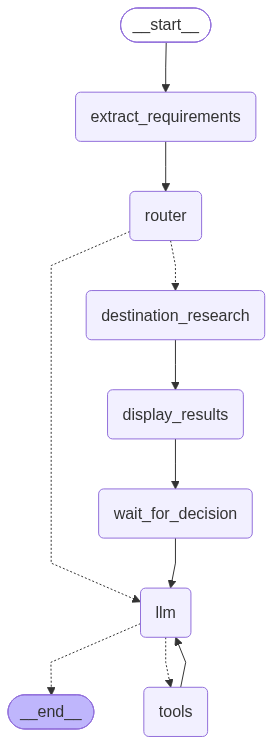

In [25]:
# Add short-term memory checkpointing
checkpointer = InMemorySaver()

builder = StateGraph(TravelState)

# ---- Nodes ----
builder.add_node("extract_requirements", extract_requirements)
builder.add_node("router", research_router)

builder.add_node("destination_research", destination_research)
builder.add_node("display_results", display_destination_results)
builder.add_node("wait_for_decision", wait_for_decision)

builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))

# ---- Edges ----
builder.add_edge(START, "extract_requirements")
builder.add_edge("extract_requirements", "router")

builder.add_conditional_edges(
    "router",
    route_destination_research,
    {
        "destination_research": "destination_research",
        "llm": "llm",
    },
)

builder.add_edge("destination_research", "display_results")
builder.add_edge("display_results", "wait_for_decision")
builder.add_edge("wait_for_decision", "llm")

builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")

# ---- Compile ----
graph = builder.compile(checkpointer=checkpointer)

display(Image(graph.get_graph().draw_mermaid_png()))

## Test with different prompts

In [25]:
async def test_travel(prompt: str):
    thread_id = str(uuid.uuid4())
    config = {"configurable": {"thread_id": thread_id}}

    print("=" * 80)
    print(f"USER: {prompt}")
    print("=" * 80)

    # First execution
    result = await graph.ainvoke(
        {
            "messages": [HumanMessage(content=prompt)],
            "requirements": None,
        },
        config=config,
    )

    # If the graph stopped at wait_for_decision
    state = await graph.aget_state(config)

    if state.next:
        print(f"\nGraph paused at: {state.next}")

        if "wait_for_decision" in state.next:
            user_input = input("\nChoose a destination (or type your preference): ")

            # Resume the same graph execution
            result = await graph.ainvoke(
                Command(resume=user_input),
                config=config,
            )

    print("\n" + "=" * 80)
    print("FINAL STATE")
    print("=" * 80)

    final_state = await graph.aget_state(config)

    print("Requirements:")
    print(final_state.values.get("requirements"))

    print("\nMessages:")
    for msg in final_state.values.get("messages", []):
        if msg.content:
            print(f"{msg.type.upper()}: {msg.content}")

**Important**: After every test, verify the agent's traces with [LangSmith](https://smith.langchain.com) for ensuring that the agent is following the correct steps and interacting with the tools correctly.

### 1. Research by broad preferences

In [48]:
test1 = "I want to travel somewhere in Europe in September for one week. " \
    "I'm interested in food, culture and good weather. My budget is €2,000 " \
    "for two people. Recommend some destinations."
await test_travel(test1)

USER: I want to travel somewhere in Europe in September for one week. I'm interested in food, culture and good weather. My budget is €2,000 for two people. Recommend some destinations.
Running destination research...

DESTINATION RECOMMENDATIONS

1. Barcelona, Spain — 9.0/10
   Barcelona is a vibrant city offering exceptional Mediterranean cuisine, world-renowned culture (Gaudi architecture, museums), and consistently good weather in September with warm, sunny days ideal for exploring. It aligns well with all user interests and fits comfortably within the €2,000 budget for two people for a week, considering it is moderately affordable compared to some other European cities.

2. Lisbon, Portugal — 8.0/10
   Lisbon is known for its rich culture (historic neighborhoods, fado music), excellent food (fresh seafood, pastries), and pleasant weather in September with mild, sunny days. It is one of the most affordable capital cities in Western Europe, making it a strong fit for the budget. The 

### 2. Research with geographical preferences

In [26]:
test2 = "I want to spend a week somewhere in Southern Europe in October. " \
    "I'm traveling with my partner and we'd like a beach destination with " \
    "good food. Our budget is €1,200."
await test_travel(test2)

USER: I want to spend a week somewhere in Southern Europe in October. I'm traveling with my partner and we'd like a beach destination with good food. Our budget is €1,200.
Running destination research...


Deserializing unregistered type __main__.TravelRequirements from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'TravelRequirements')]
Deserializing unregistered type __main__.DestinationCandidate from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('__main__', 'DestinationCandidate')]



DESTINATION RECOMMENDATIONS

1. Algarve, Portugal — 9.0/10
   A coastal region in Southern Europe with stunning beaches, warm October weather, and a renowned culinary scene focused on fresh seafood and local wines. It offers excellent value for money, aligning well with a €1,200 budget for two over a week, and matches the beach and food interests.

2. Sardinia, Italy — 8.0/10
   An Italian island in the Mediterranean with beautiful beaches and clear waters, ideal for a beach holiday. October provides mild weather and fewer crowds. It is known for its distinctive cuisine, including seafood and local specialties, which fits the food interest. The budget may be tighter, but it is still feasible with careful planning.

3. Costa del Sol, Spain — 8.0/10
   A popular coastal area in Southern Europe with numerous beaches and a vibrant culinary scene featuring tapas, seafood, and regional dishes. October offers pleasant weather and lower prices compared to peak season. It aligns well with beac

### 3. Research with complex requirements

In [27]:
test3 = "Help me choose a destination for a 10-day trip in Japan in April. " \
    "We are two people interested in culture, food and nature, and we'd " \
    "prefer places that are not excessively crowded. Our budget is €5,000."
await test_travel(test3)

USER: Help me choose a destination for a 10-day trip in Japan in April. We are two people interested in culture, food and nature, and we'd prefer places that are not excessively crowded. Our budget is €5,000.
Running destination research...

DESTINATION RECOMMENDATIONS

1. Kanazawa (Ishikawa Prefecture) — 9.0/10
   Kanazawa is a cultural gem on the Sea of Japan coast, often called 'Little Kyoto' but far less crowded. It offers superb traditional culture (Nagamachi samurai district, Higashi Chaya geisha quarter, 21st Century Museum of Contemporary Art), outstanding food (fresh sushi and seafood from one of Japan's top three morning markets, Kaga cuisine), and beautiful nature (Kenrokuen, one of Japan's finest landscape gardens, plus nearby Noto Peninsula coast). In April, cherry blossoms frame the city without the overwhelming crowds of Kyoto. The region is well-connected by shinkansen from Tokyo (2.5 hrs). Budget is comfortable for this area — it's more affordable than Tokyo/Kyoto. **S

### 4. Destination already known — no need to research

In [28]:
test4 = "I'm going to Paris from September 10 to September 17, 2026 " \
    "for two people. Find suitable hotels with a budget of €1,000."
await test_travel(test4)

USER: I'm going to Paris from September 10 to September 17, 2026 for two people. Find suitable hotels with a budget of €1,000.

FINAL STATE
Requirements:
origin='' destination='Paris' travel_dates='2026-09-10 to 2026-09-17' duration_days=7 travelers=2 budget=1000.0 currency='EUR' interests=[] constraints=[]

Messages:
HUMAN: I'm going to Paris from September 10 to September 17, 2026 for two people. Find suitable hotels with a budget of €1,000.
TOOL: [{'type': 'text', 'text': 'Found 5 criteria-matched accommodation offers in Paris after checking 5 candidate properties. 5 booking-ready. 5 final-trip-cost-ready. Best verified match: EUR 53/night (EUR 476 total) at Adonis Paris Sud (Agoda room rate).', 'id': 'lc_c1af9748-8af8-488b-878f-fe2a2456f70a'}, {'type': 'text', 'text': '{\n  "success": true,\n  "need": {\n    "location": "Paris",\n    "check_in": "2026-09-10",\n    "check_out": "2026-09-17",\n    "adults": 2,\n    "currency": "EUR"\n  },\n  "count": 5,\n  "matching_count": 5,\n  "bo